# Focus scan (simulations)
Simulated version of `analysis_tools/focus-scan.ipynb`: image widths of one telescope over a focus scan, one
sim_telarray tag per lens (thin/thick) and focal offset (`make_configs.py`, `submit_focus.sh`), every step on the same
256 proton showers with the same seeds, so the steps differ only in the optics. Every image is pedestal-subtracted,
cleaned and parameterized with `heap.process_dataset.process_image()`, with the pedestal and pedvar from the step's
pedestal frames (as `heap.process_simulation`) and a flat gain, like the data.

Step is the focal offset in mm (camera plane at the lens's 60.78 cm focal length + offset). The real scan's focuser
moves 250 steps/mm (its 300-step increments are 1.2 mm) and its zero is unknown, so compare shapes, not positions.

# Imports

In [1]:
import glob
import json
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde

from heap import diagnostics as dg
from heap.make_pedestals import calculate_pedestal_and_pedvar
from heap.process_dataset import process_image
from heap.process_simulation import plot_image_grid, processed_path
from heap.read_simtel import read_events
from simulation_tools.run_simulation import load_config

# Globals

In [2]:
CONFIGS = sorted(Path("configs").glob("*.yaml")) # one per lens and focal offset, see make_configs.py
TELESCOPE = "Winter"
TEL_ID = 2 # Winter is the CORSIKA card's second TELESCOPE line

# pedestals, as heap.process_simulation
NSIG = 5.0
FIT_GAUSSIAN = True

# cleaning: each step's config's pipeline section (image_threshold, border_threshold, keep_brightest_island)
GAIN = np.ones(1024) # flat
REPROCESS = False # redo a step even if its cached processing matches

# cuts
MIN_NPIX = 3

# plots
LENS = "thin" # lens of the per-step plots; the width summary shows both
PLOT_STEPS = [-50, -30, -15, -10, -5, 0, 5, 10, 15, 30, 50] # focal offsets [mm] of the per-step plots

# Read data
Each step's Winter images, processed once and cached in `heap.process_simulation`'s layout,
`<processed_dir>/<name>/<tag>/T2/<name>/<name>.npz`. A step is reprocessed when its settings or number of simtel files
change (e.g. it was read while its jobs were still running).

In [3]:
SETTINGS = {"tel_id": TEL_ID, "nsig": NSIG, "fit_gaussian": FIT_GAUSSIAN}


def process_step(cfg):
    """One step's Winter images: (params, cleaned images), or None if it has no simtel files yet."""
    name, tag = cfg["production"]["name"], cfg["sim_telarray"]["tag"]
    files = sorted(glob.glob(str(cfg["paths"]["output_dir"] / "simtel" / tag / f"{name}_run*.simtel.zst")))
    if not files:
        return None
    settings = SETTINGS | cfg["pipeline"] | {"n_files": len(files)}
    path = processed_path(cfg) / f"T{TEL_ID}" / name / f"{name}.npz"
    settings_path = processed_path(cfg) / f"{name}_processing.json"
    if path.exists() and not REPROCESS and settings_path.exists() and json.loads(settings_path.read_text()) == settings:
        npz = np.load(path)
        return pd.DataFrame({col: npz[col] for col in npz.files if col != "cleaned_images"})

    telescopes, showers = read_events(files)
    tel = telescopes[TEL_ID]
    pedestal, pedvar = calculate_pedestal_and_pedvar(tel["pedestal_frames"].reshape(-1, 1024), nsig=NSIG, fit_gaussian=FIT_GAUSSIAN)
    results = [
        process_image(image, pedestal, pedvar, GAIN, **cfg["pipeline"])
        for image in tel["images"].reshape(-1, 1024)
    ]
    cleaned = np.stack([cleaned for cleaned, _ in results]).astype(np.float32)
    params = pd.DataFrame([params for _, params in results])
    params["Run"], params["EventID"] = tel["run"], tel["event_id"]
    truth = pd.DataFrame({key: showers[key] for key in ["run", "event_id", "energy"]}).rename(columns={"run": "Run", "event_id": "EventID"})
    params = params.merge(truth, on=["Run", "EventID"], how="left")

    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(path, cleaned_images=cleaned, **{col: params[col].values for col in params.columns})
    settings_path.write_text(json.dumps(settings, indent=2))
    print(f"{tag}: {len(files)} files, {len(params)} {TELESCOPE} images")
    return params


dfs = []
cfgs = {} # tag -> config
for config in CONFIGS:
    cfg = load_config(config)
    params = process_step(cfg)
    if params is None:
        print(f"{cfg['sim_telarray']['tag']}: no simtel files yet")
        continue
    optics = cfg["sim_telarray"]["optics"]
    params.insert(0, "ImageIndex", np.arange(len(params))) # row in the step's cleaned_images
    params.insert(0, "Tag", cfg["sim_telarray"]["tag"])
    params.insert(0, "Step", int(round(optics["focal_offset"] * 10))) # mm
    params.insert(0, "Lens", "thick" if optics["thick_lens"] else "thin")
    dfs.append(params)
    cfgs[cfg["sim_telarray"]["tag"]] = cfg

df = pd.concat(dfs, ignore_index=True)
print(f"{len(df)} images in {df.Tag.nunique()} steps")

175799 images in 74 steps


In [4]:
df = df.dropna(subset=["length", "width", "miss", "distance", "alpha"])
df = df[df.width > 0]
df = df[df.N_pix >= MIN_NPIX].reset_index(drop=True)
print(f"{len(df)} after cuts")

175320 after cuts


In [5]:
df.describe()

,Step,ImageIndex,N_pix,size,x_c,y_c,s_xx,s_yy,s_xy,length,width,miss,distance,alpha,phi,Run,EventID,energy
count,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000
mean,-2.916393,1267.703303,34.388290,3150.440375,-0.084556,0.001656,0.270313,0.274135,-0.000170,0.593244,0.384232,2.695114,3.717747,50.777951,178.848720,130.902806,9732.474424,99.692287
std,19.079323,787.954368,24.300277,5179.921408,2.815477,2.797131,0.177276,0.182295,0.080954,0.158287,0.140785,1.587860,1.391503,25.401254,102.369893,74.156243,5816.529859,165.750891
min,-50.000000,0.000000,3.000000,60.363501,-4.787698,-4.789353,0.001166,0.001808,-0.648627,0.098082,0.033706,0.000035,0.007449,0.000823,0.003910,1.000000,100.000000,6.000678
25%,-9.000000,594.000000,19.000000,1232.984450,-2.574508,-2.477644,0.143356,0.144016,-0.045253,0.488287,0.287284,1.281079,2.772268,30.303324,92.494586,67.000000,4605.000000,28.500584
50%,-2.000000,1205.000000,29.000000,1907.685760,-0.235207,0.000081,0.239184,0.238851,-0.000636,0.589044,0.373676,2.709973,3.922854,54.298243,178.871418,129.000000,9408.000000,50.317272
75%,6.000000,1898.250000,42.000000,3254.067072,2.359950,2.371739,0.355848,0.362220,0.044689,0.689801,0.465297,4.123857,4.716377,72.385387,267.355463,196.000000,14817.000000,98.211617
max,50.000000,3029.000000,461.000000,123334.463969,4.791498,4.788911,1.756048,1.780372,0.672080,1.411233,1.265510,6.642439,6.703015,89.999882,359.996000,256.000000,20019.000000,1754.132690


In [6]:
df

,Lens,Step,Tag,ImageIndex,N_pix,size,x_c,y_c,s_xx,s_yy,s_xy,length,width,miss,distance,alpha,phi,Run,EventID,energy
0,thick,-1,thick_m01mm,0,17,916.271798,2.632464,1.754453,0.117904,0.357772,-0.151497,0.656553,0.211219,3.133773,3.163538,82.134193,115.816380,1,1610,19.307072
1,thick,-1,thick_m01mm,1,17,1279.392387,0.785399,-2.080856,0.172281,0.053109,-0.022333,0.419915,0.221498,1.907433,2.224144,59.048556,349.727072,1,4911,35.058125
2,thick,-1,thick_m01mm,2,14,831.894509,2.863527,-2.449108,0.192920,0.125385,-0.096009,0.510809,0.239538,0.343359,3.768013,5.228310,324.688703,1,4919,35.058125
3,thick,-1,thick_m01mm,3,72,5332.029885,-2.552948,-2.807589,0.435895,0.473790,-0.035119,0.703382,0.644157,3.630987,3.794746,73.106356,300.826033,1,8107,29.890778
4,thick,-1,thick_m01mm,4,3,235.012518,0.280775,4.598916,0.066614,0.022189,-0.035997,0.294449,0.045853,4.152824,4.607479,64.332424,150.838716,1,9313,56.474033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175315,thin,50,thin_p50mm,880,32,1748.704760,-1.967991,3.524669,0.326514,0.281669,-0.003665,0.571674,0.530445,3.353869,4.036866,56.182053,175.358759,256,9807,113.199020
175316,thin,50,thin_p50mm,881,83,4121.677995,-0.667136,2.188042,0.906598,0.906575,0.139611,1.022838,0.875771,2.018961,2.287488,61.958905,44.997606,256,9815,113.199020
175317,thin,50,thin_p50mm,882,44,2355.327538,-3.909761,1.948325,0.228207,0.777022,0.062935,0.885520,0.470194,4.104106,4.368318,69.970461,83.541391,256,10700,306.782684
175318,thin,50,thin_p50mm,883,18,1156.537822,-1.821414,-4.515366,0.348963,0.068418,-0.055935,0.599754,0.240160,4.777835,4.868889,78.901825,169.129945,256,16008,36.248009


# Widths
`LENS` at the `PLOT_STEPS` offsets, then the summary of every step for both lenses.

In [7]:
plot_df = df[(df.Lens == LENS) & df.Step.isin(PLOT_STEPS)]
steps = sorted(plot_df.Step.unique())
cmap = plt.get_cmap('rainbow_r')

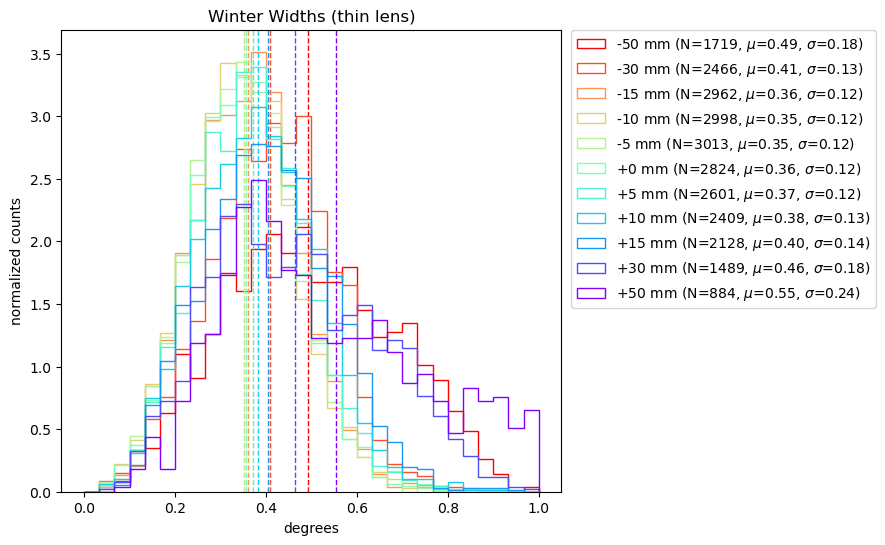

In [8]:
fig, ax = plt.subplots(figsize=(8,6))

for i, step in enumerate(steps):
    color = cmap(i / max(1, len(steps)-1))

    data = plot_df[plot_df.Step==step]
    mean = data.width.mean()
    sigma = data.width.std()

    ax.hist(data.width, bins=30, range=(0,1), histtype='step', density=True,
            label=f"{step:+d} mm (N={len(data)}, $\\mu$={mean:.2f}, $\\sigma$={sigma:.2f})", color=color)
    ax.axvline(mean, color=color, linestyle='--', linewidth=1)


ax.set_title(f'{TELESCOPE} Widths ({LENS} lens)')
ax.set_xlabel('degrees')
ax.set_ylabel('normalized counts')

fig.subplots_adjust(right=0.75)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.show()

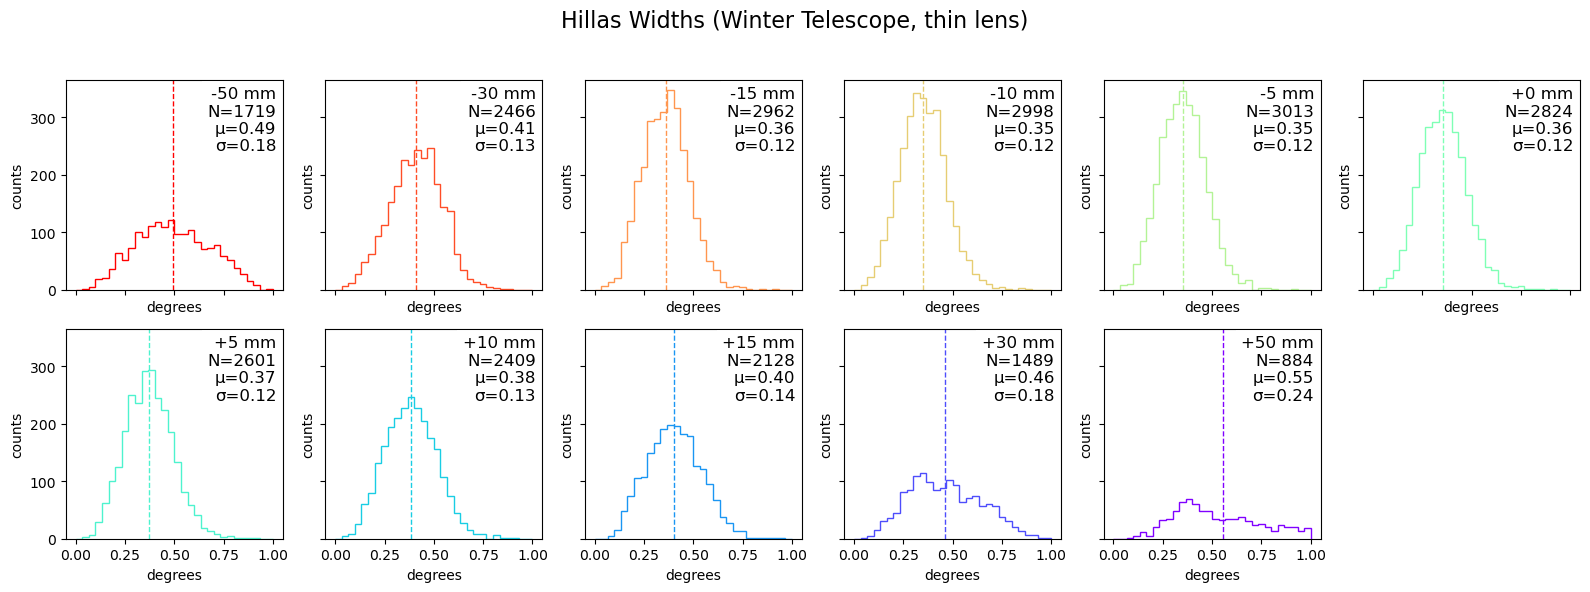

In [9]:
fig, axs = plt.subplots(2, int(np.ceil(len(steps)/2)), figsize=(16,6),sharex=True,sharey=True)
axs = axs.flatten()

for i, step in enumerate(steps):
    color = cmap(i / max(1, len(steps)-1))

    data = plot_df[plot_df.Step==step]
    mean = data.width.mean()
    sigma = data.width.std()

    axs[i].hist(data.width, bins=30, range=(0,1), histtype='step', color=color)
    axs[i].axvline(mean, color=color, linestyle='--', linewidth=1)

    info = f"{step:+d} mm\nN={len(data)}\nμ={mean:.2f}\nσ={sigma:.2f}"
    axs[i].text(0.97, 0.97, info, transform=axs[i].transAxes, ha='right', va='top', fontsize=12, color='k',
                bbox=dict(facecolor='white', alpha=0.75, edgecolor=None, linewidth=0))

for j in range(len(steps), len(axs)):
    axs[j].axis('off')

fig.suptitle(f'Hillas Widths ({TELESCOPE} Telescope, {LENS} lens)',fontsize=16)

for ax in axs:
    ax.set_xlabel('degrees')
    ax.set_ylabel('counts')

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [10]:
stats = df.groupby(["Lens", "Step"]).width.agg(["count", "mean", "std", "sem"])
stats

count      mean       std       sem
Lens  Step                                     
thick -50    1631  0.490595  0.189152  0.004684
      -45    1805  0.467861  0.169351  0.003986
      -40    1991  0.451306  0.153207  0.003434
      -35    2203  0.426515  0.142647  0.003039
      -30    2389  0.405643  0.132826  0.002718
...           ...       ...       ...       ...
thin   30    1489  0.462981  0.180950  0.004689
       35    1281  0.486513  0.194385  0.005431
       40    1134  0.501592  0.214313  0.006364
       45     987  0.533625  0.225586  0.007180
       50     884  0.553966  0.244499  0.008223

[74 rows x 4 columns]

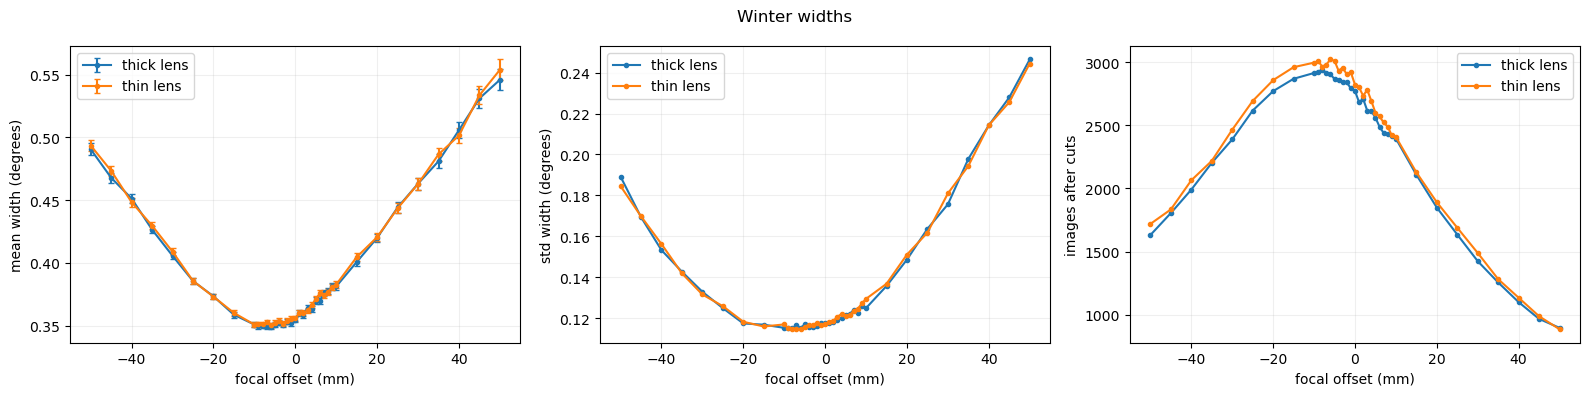

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for lens, s in stats.groupby(level="Lens"):
    s = s.droplevel("Lens")
    axs[0].errorbar(s.index, s["mean"], yerr=s["sem"], marker="o", markersize=3, capsize=2, label=f"{lens} lens")
    axs[1].plot(s.index, s["std"], marker="o", markersize=3, label=f"{lens} lens")
    axs[2].plot(s.index, s["count"], marker="o", markersize=3, label=f"{lens} lens")
axs[0].set(xlabel="focal offset (mm)", ylabel="mean width (degrees)")
axs[1].set(xlabel="focal offset (mm)", ylabel="std width (degrees)")
axs[2].set(xlabel="focal offset (mm)", ylabel="images after cuts")
for ax in axs:
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle(f"{TELESCOPE} widths")
fig.tight_layout()
plt.show()

# Width vs distance

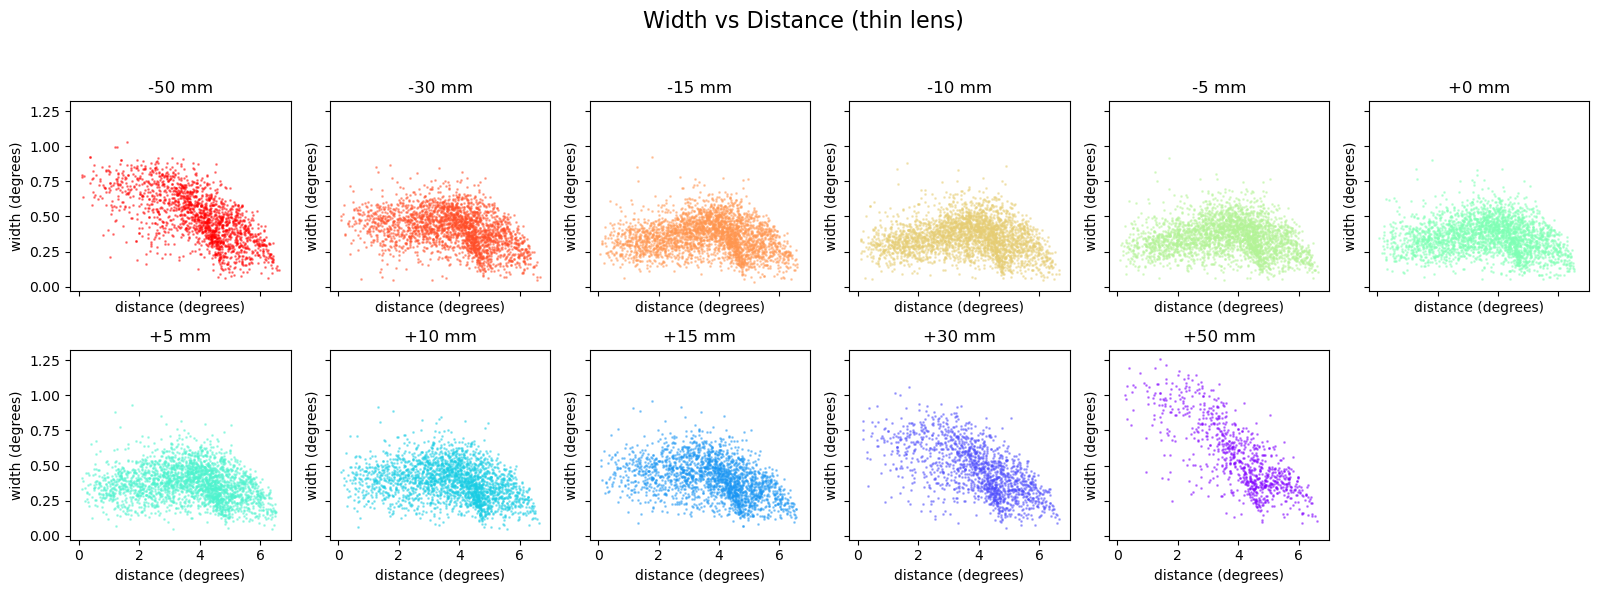

In [12]:
fig, axs = plt.subplots(2, int(np.ceil(len(steps)/2)), figsize=(16,6),sharex=True,sharey=True)
axs = axs.flatten()

for i, step in enumerate(steps):
    color = cmap(i / max(1, len(steps)-1))

    data = plot_df[plot_df.Step==step]

    axs[i].scatter(data.distance,data.width, color=color, s=1, alpha=0.4)

    axs[i].set_title(f"{step:+d} mm")

for j in range(len(steps), len(axs)):
    axs[j].axis('off')

fig.suptitle(f'Width vs Distance ({LENS} lens)',fontsize=16)

for ax in axs:
    ax.set_xlabel('distance (degrees)')
    ax.set_ylabel('width (degrees)')

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

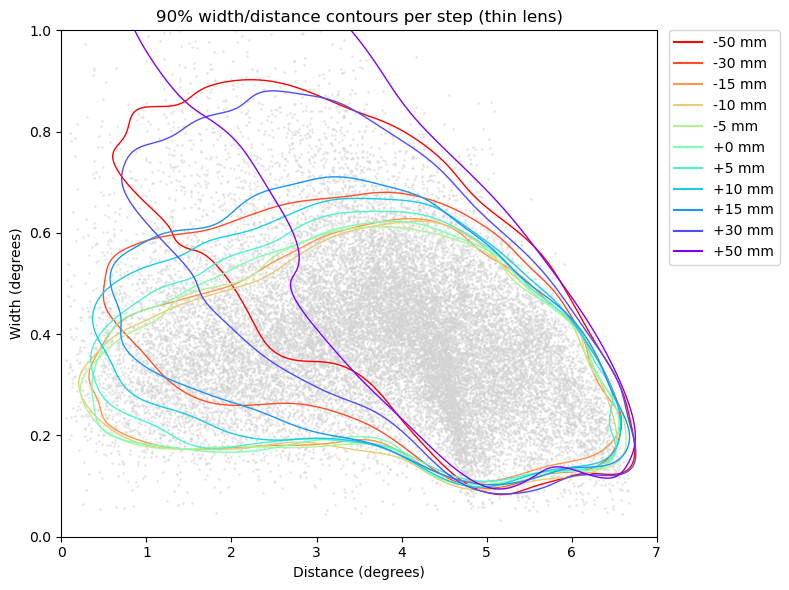

In [13]:
n_steps = len(steps)

# common grid bounds
xmin, xmax = 0, 7
ymin, ymax = 0, 1

xi = np.linspace(xmin, xmax, 300)
yi = np.linspace(ymin, ymax, 300)
xx, yy = np.meshgrid(xi, yi)
positions = np.vstack([xx.ravel(), yy.ravel()])

fig, ax = plt.subplots(figsize=(8,6))

# faint background points
ax.scatter(plot_df.distance, plot_df.width, s=1, color='lightgray', alpha=0.4)

legend_handles = []

for i, step in enumerate(steps):
    data = plot_df[plot_df.Step == step]
    x = data.distance.values
    y = data.width.values
    if len(data) < 5:
        continue
    kde = gaussian_kde(np.vstack([x, y]))
    zz = np.reshape(kde(positions), xx.shape)

    # compute density threshold for 90% mass
    zz_flat = zz.ravel()
    idx = np.argsort(zz_flat)[::-1]
    zz_sorted = zz_flat[idx]
    cumsum = np.cumsum(zz_sorted)
    cumsum /= cumsum[-1]
    level90 = zz_sorted[np.searchsorted(cumsum, 0.90)]

    color = cmap(i / max(1, n_steps-1))
    legend_handles.append(Line2D([0], [0], color=color, linestyle='solid', linewidth=1.5, label=f'{step:+d} mm'))

    ax.contour(xx, yy, zz, levels=[level90], colors=[color], linestyles=['solid'], linewidths=1.0)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_xlabel('Distance (degrees)')
ax.set_ylabel('Width (degrees)')
ax.set_title(f'90% width/distance contours per step ({LENS} lens)')

ax.legend(handles=legend_handles, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

plt.tight_layout()
plt.show()

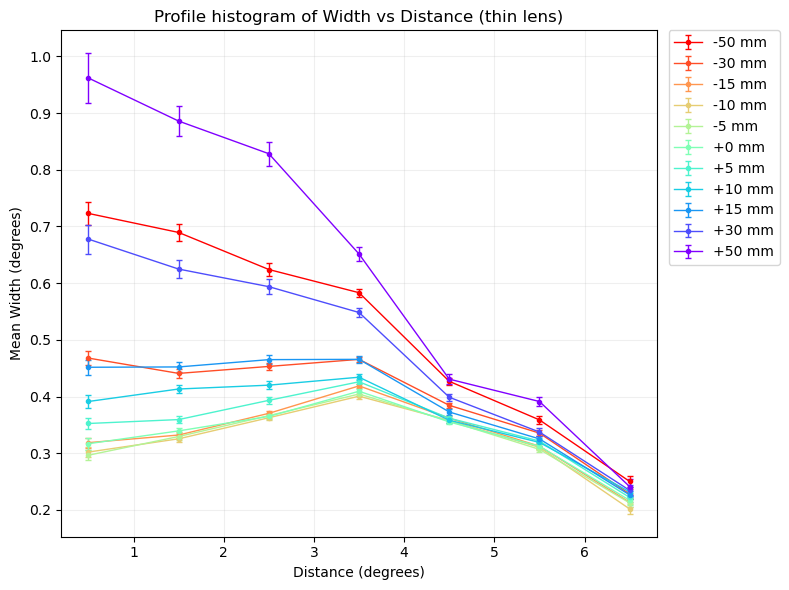

In [14]:
n_steps = len(steps)

fig, ax = plt.subplots(figsize=(8, 6))

# profile histogram: mean width in distance bins
bin_width = 1  # degrees; change this to widen or narrow the bins
xmin, xmax = 0, 7
bin_edges = np.arange(xmin, xmax + bin_width, bin_width)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

for i, step in enumerate(steps):
    data = plot_df[plot_df.Step == step]
    if len(data) < 5:
        continue

    color = cmap(i / max(1, n_steps - 1))
    bin_index = np.digitize(data.distance.values, bin_edges) - 1

    means = []
    errors = []
    centers = []

    for b in range(len(bin_edges) - 1):
        mask = bin_index == b
        if not np.any(mask):
            continue
        widths = data.width.values[mask]
        centers.append(bin_centers[b])
        means.append(np.mean(widths))
        errors.append(np.std(widths) / np.sqrt(len(widths)) if len(widths) > 1 else 0.0)

    ax.errorbar(
        centers,
        means,
        yerr=errors,
        color=color,
        marker='o',
        markersize=3,
        linewidth=1,
        capsize=2,
        label=f'{step:+d} mm',
    )

ax.set_xlabel('Distance (degrees)')
ax.set_ylabel('Mean Width (degrees)')
ax.set_title(f'Profile histogram of Width vs Distance ({LENS} lens)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Brightness vs distance

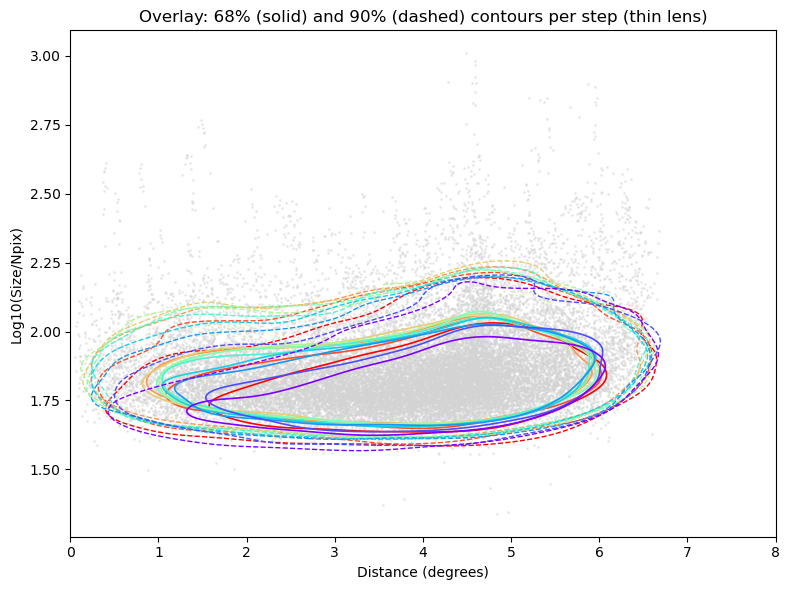

In [15]:
n_steps = len(steps)

# common grid bounds
xmin, xmax = 0, 8
y_all = np.log10(plot_df["size"].values / plot_df.N_pix.values)
ymin, ymax = np.nanmin(y_all), np.nanmax(y_all)
ypad = 0.05 * (ymax - ymin) if ymax>ymin else 0.1
ymin -= ypad; ymax += ypad

xi = np.linspace(xmin, xmax, 300)
yi = np.linspace(ymin, ymax, 300)
xx, yy = np.meshgrid(xi, yi)
positions = np.vstack([xx.ravel(), yy.ravel()])

fig, ax = plt.subplots(figsize=(8,6))

# faint background points
ax.scatter(plot_df.distance, y_all, s=1, color='lightgray', alpha=0.4)

for i, step in enumerate(steps):
    data = plot_df[plot_df.Step == step]
    x = data.distance.values
    y = np.log10(data["size"].values / data.N_pix.values)
    if len(data) < 5:
        continue
    kde = gaussian_kde(np.vstack([x, y]))
    zz = np.reshape(kde(positions), xx.shape)

    # compute density thresholds for 68% and 90% mass
    zz_flat = zz.ravel()
    idx = np.argsort(zz_flat)[::-1]
    zz_sorted = zz_flat[idx]
    cumsum = np.cumsum(zz_sorted)
    cumsum /= cumsum[-1]
    level68 = zz_sorted[np.searchsorted(cumsum, 0.68)]
    level90 = zz_sorted[np.searchsorted(cumsum, 0.90)]

    color = cmap(i / max(1, n_steps-1))

    # draw contours: 68% solid, 90% dashed
    ax.contour(xx, yy, zz, levels=[level68], colors=[color], linestyles=['solid'], linewidths=1.2)
    ax.contour(xx, yy, zz, levels=[level90], colors=[color], linestyles=['dashed'], linewidths=1.0)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_xlabel('Distance (degrees)')
ax.set_ylabel('Log10(Size/Npix)')
ax.set_title(f'Overlay: 68% (solid) and 90% (dashed) contours per step ({LENS} lens)')
plt.tight_layout()
plt.show()

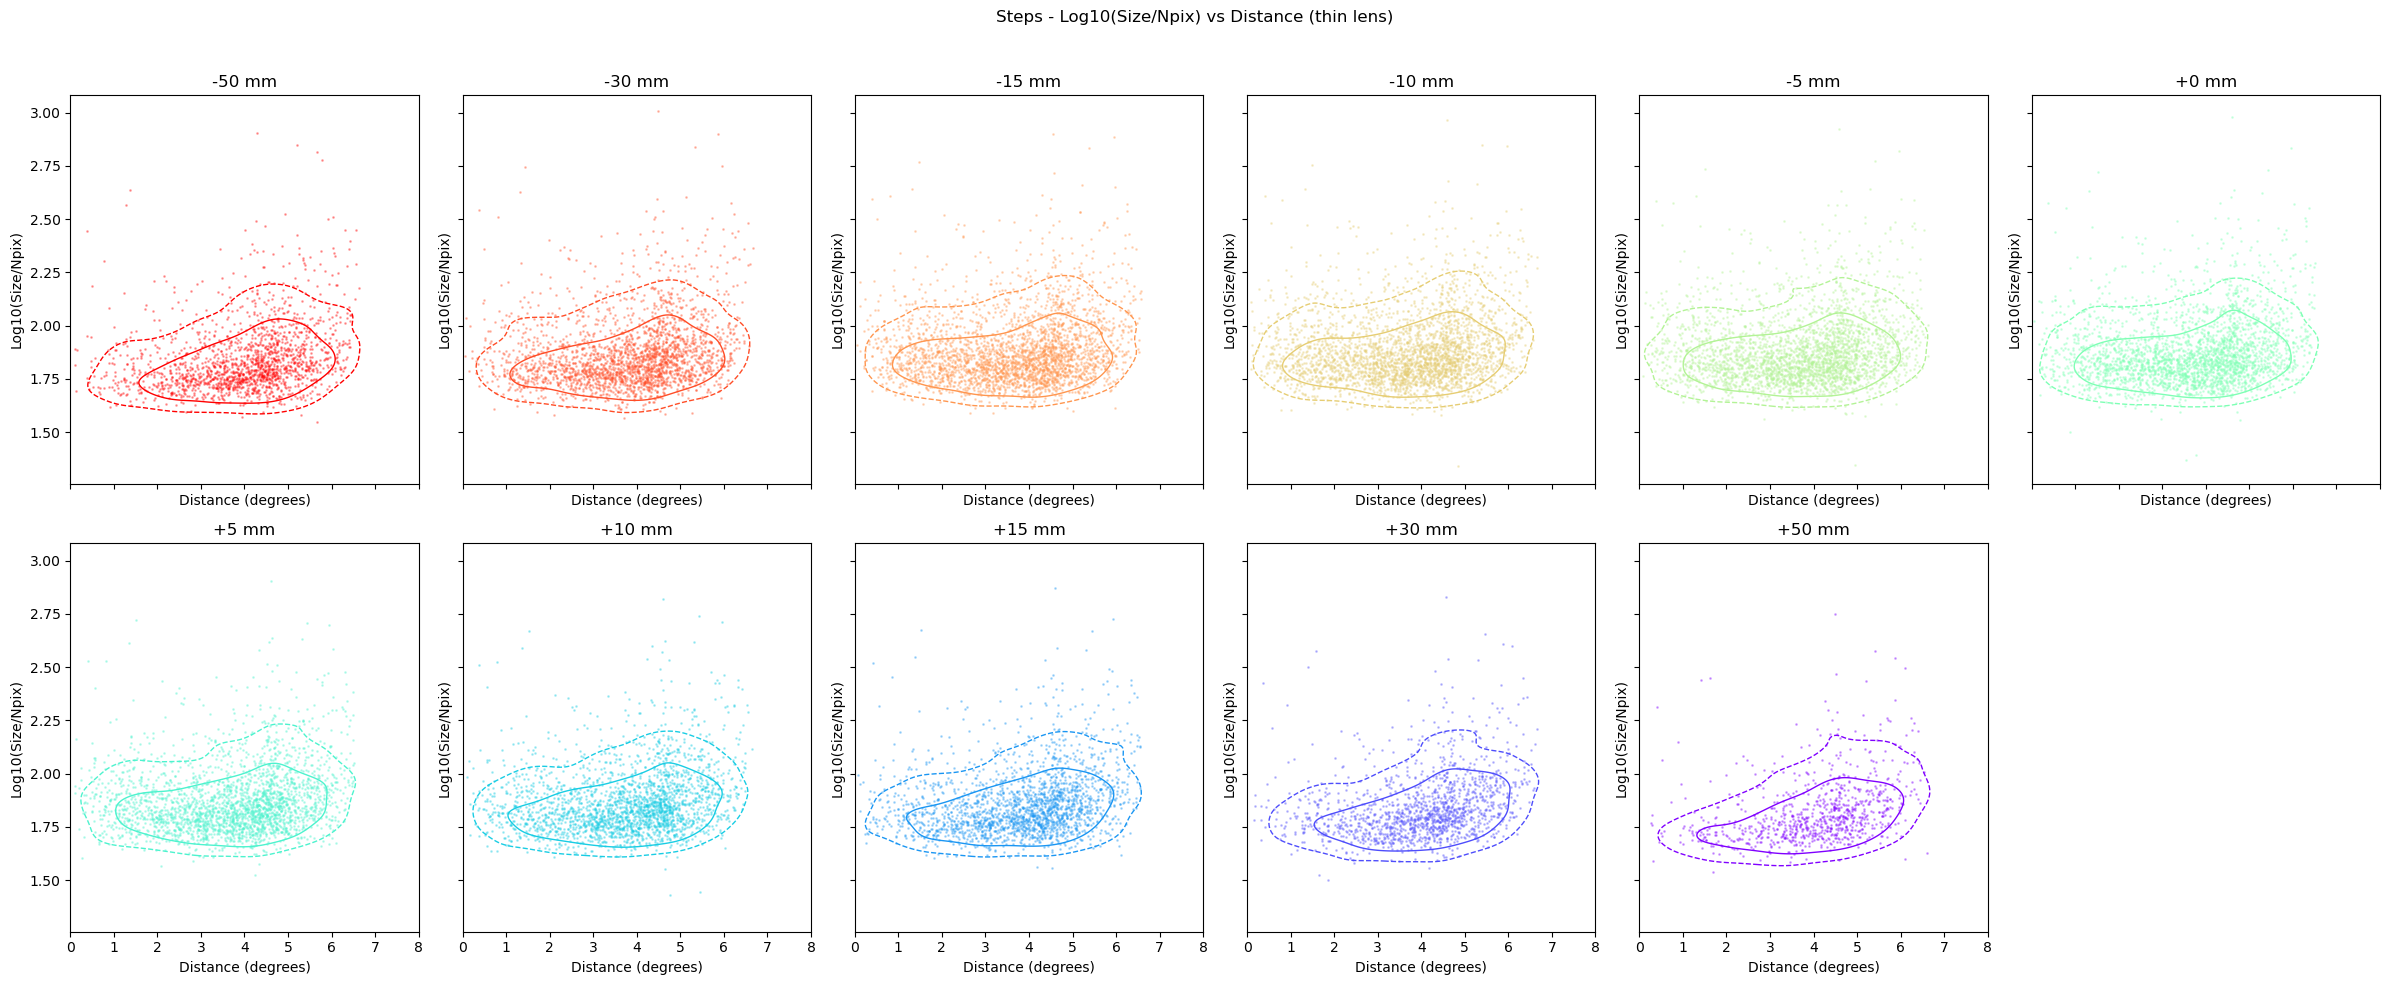

In [16]:
n_steps = len(steps)
ncols = int(np.ceil(n_steps/2))
fig, axs = plt.subplots(2, ncols, figsize=(4*ncols, 10), sharex=True, sharey=True)
axs = axs.flatten()
fig.suptitle(f"Steps - Log10(Size/Npix) vs Distance ({LENS} lens)")

for i, step in enumerate(steps):
    ax = axs[i]
    data = plot_df[plot_df.Step == step]
    x = data.distance.values
    y = np.log10(data["size"].values / data.N_pix.values)

    if len(data) < 5:
        ax.text(0.5,0.5,'too few points', transform=ax.transAxes, ha='center')
        ax.set_title(f"{step:+d} mm")
        continue

    # grid for KDE
    xmin, xmax = 0, 8
    ymin, ymax = np.nanmin(y), np.nanmax(y)
    ypad = 0.05 * (ymax - ymin) if ymax>ymin else 0.1
    ymin -= ypad; ymax += ypad
    xi = np.linspace(xmin, xmax, 200)
    yi = np.linspace(ymin, ymax, 200)
    xx, yy = np.meshgrid(xi, yi)
    positions = np.vstack([xx.ravel(), yy.ravel()])

    # compute KDE
    try:
        kde = gaussian_kde(np.vstack([x, y]))
    except Exception as e:
        ax.scatter(x, y, s=2, alpha=0.3)
        ax.set_title(f"{step:+d} mm")
        continue
    zz = np.reshape(kde(positions), xx.shape)

    # find contour levels for 68% and 90%
    zz_flat = zz.ravel()
    idx = np.argsort(zz_flat)[::-1]
    zz_sorted = zz_flat[idx]
    cumsum = np.cumsum(zz_sorted)
    cumsum /= cumsum[-1]
    level68 = zz_sorted[np.searchsorted(cumsum, 0.68)]
    level90 = zz_sorted[np.searchsorted(cumsum, 0.90)]

    color = cmap(i / max(1, n_steps-1))

    # scatter and unfilled contours
    ax.scatter(x, y, color=color, s=1, alpha=0.3)
    ax.contour(xx, yy, zz, levels=[level68], colors=[color], linestyles=['solid'], linewidths=1.0)
    ax.contour(xx, yy, zz, levels=[level90], colors=[color], linestyles=['dashed'], linewidths=1.0)

    ax.set_title(f"{step:+d} mm")
    ax.set_xlim(xmin, xmax)
    ax.set_xlabel('Distance (degrees)')
    ax.set_ylabel('Log10(Size/Npix)')

# turn off unused axes
for j in range(n_steps, len(axs)):
    axs[j].axis('off')

fig.tight_layout(rect=[0,0,1,0.96])
plt.show()

# Events
Cleaned images after cuts at `EVENT_STEP` (`LENS` lens) with their Hillas ellipses; the panel title's number is
`ImageIndex`. Run again for other random events.

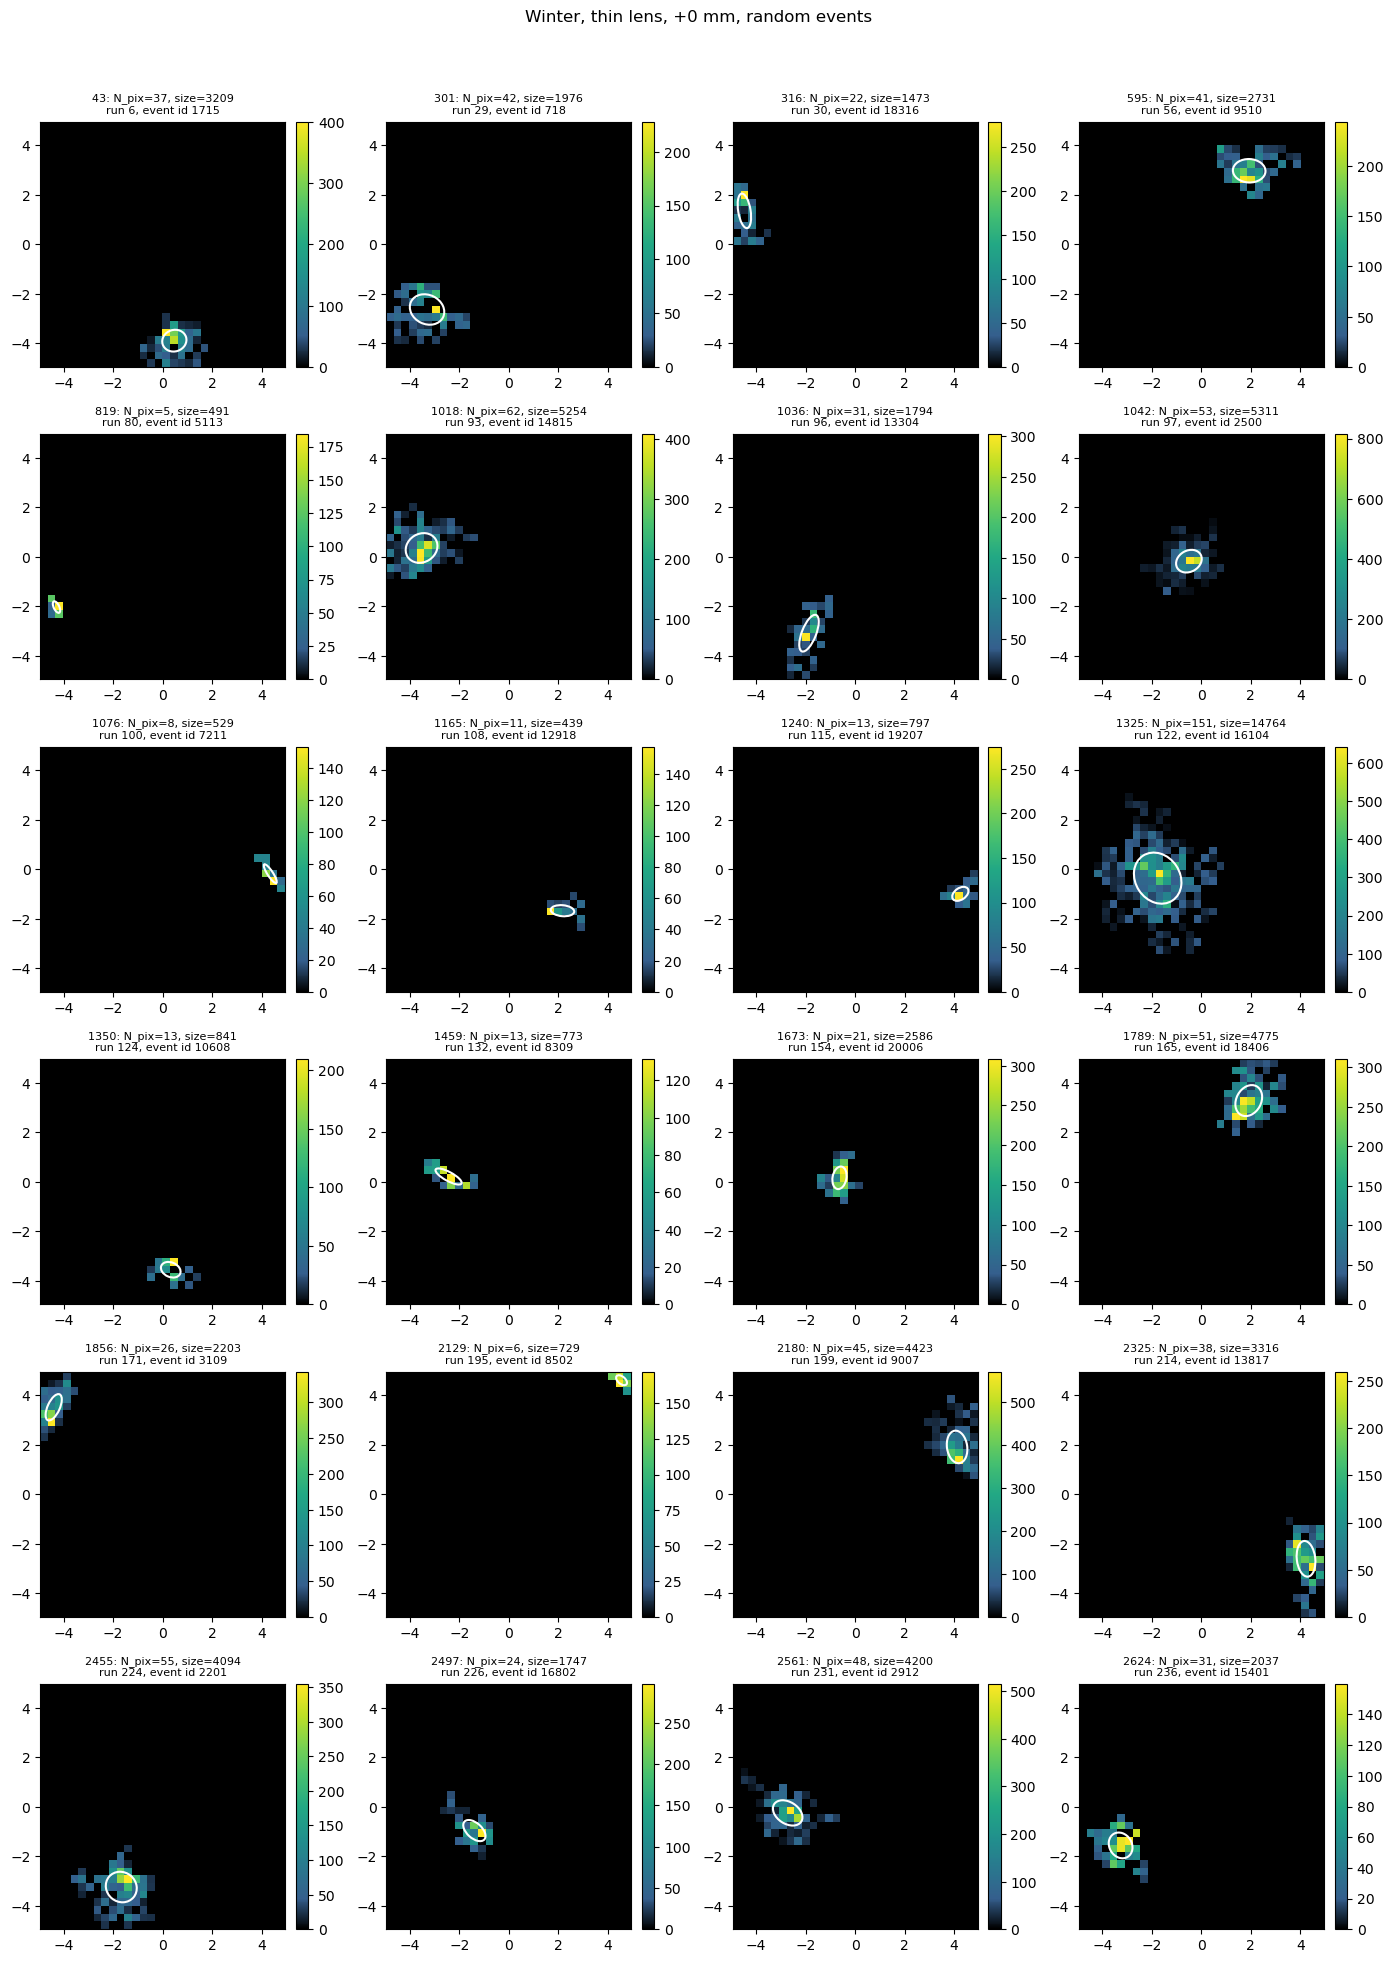

In [17]:
N_EVENTS = 24
EVENT_STEP = 0 # focal offset [mm]
step_df = df[(df.Lens == LENS) & (df.Step == EVENT_STEP)]
step_cfg = cfgs[step_df.Tag.iloc[0]]
name = step_cfg["production"]["name"]

fig = plot_image_grid(processed_path(step_cfg), name, f"T{TEL_ID}",
                      np.sort(np.random.default_rng().choice(step_df.ImageIndex, size=min(N_EVENTS, len(step_df)), replace=False)))
fig.suptitle(f"{TELESCOPE}, {LENS} lens, {EVENT_STEP:+d} mm, random events", y=1.02)
plt.show()

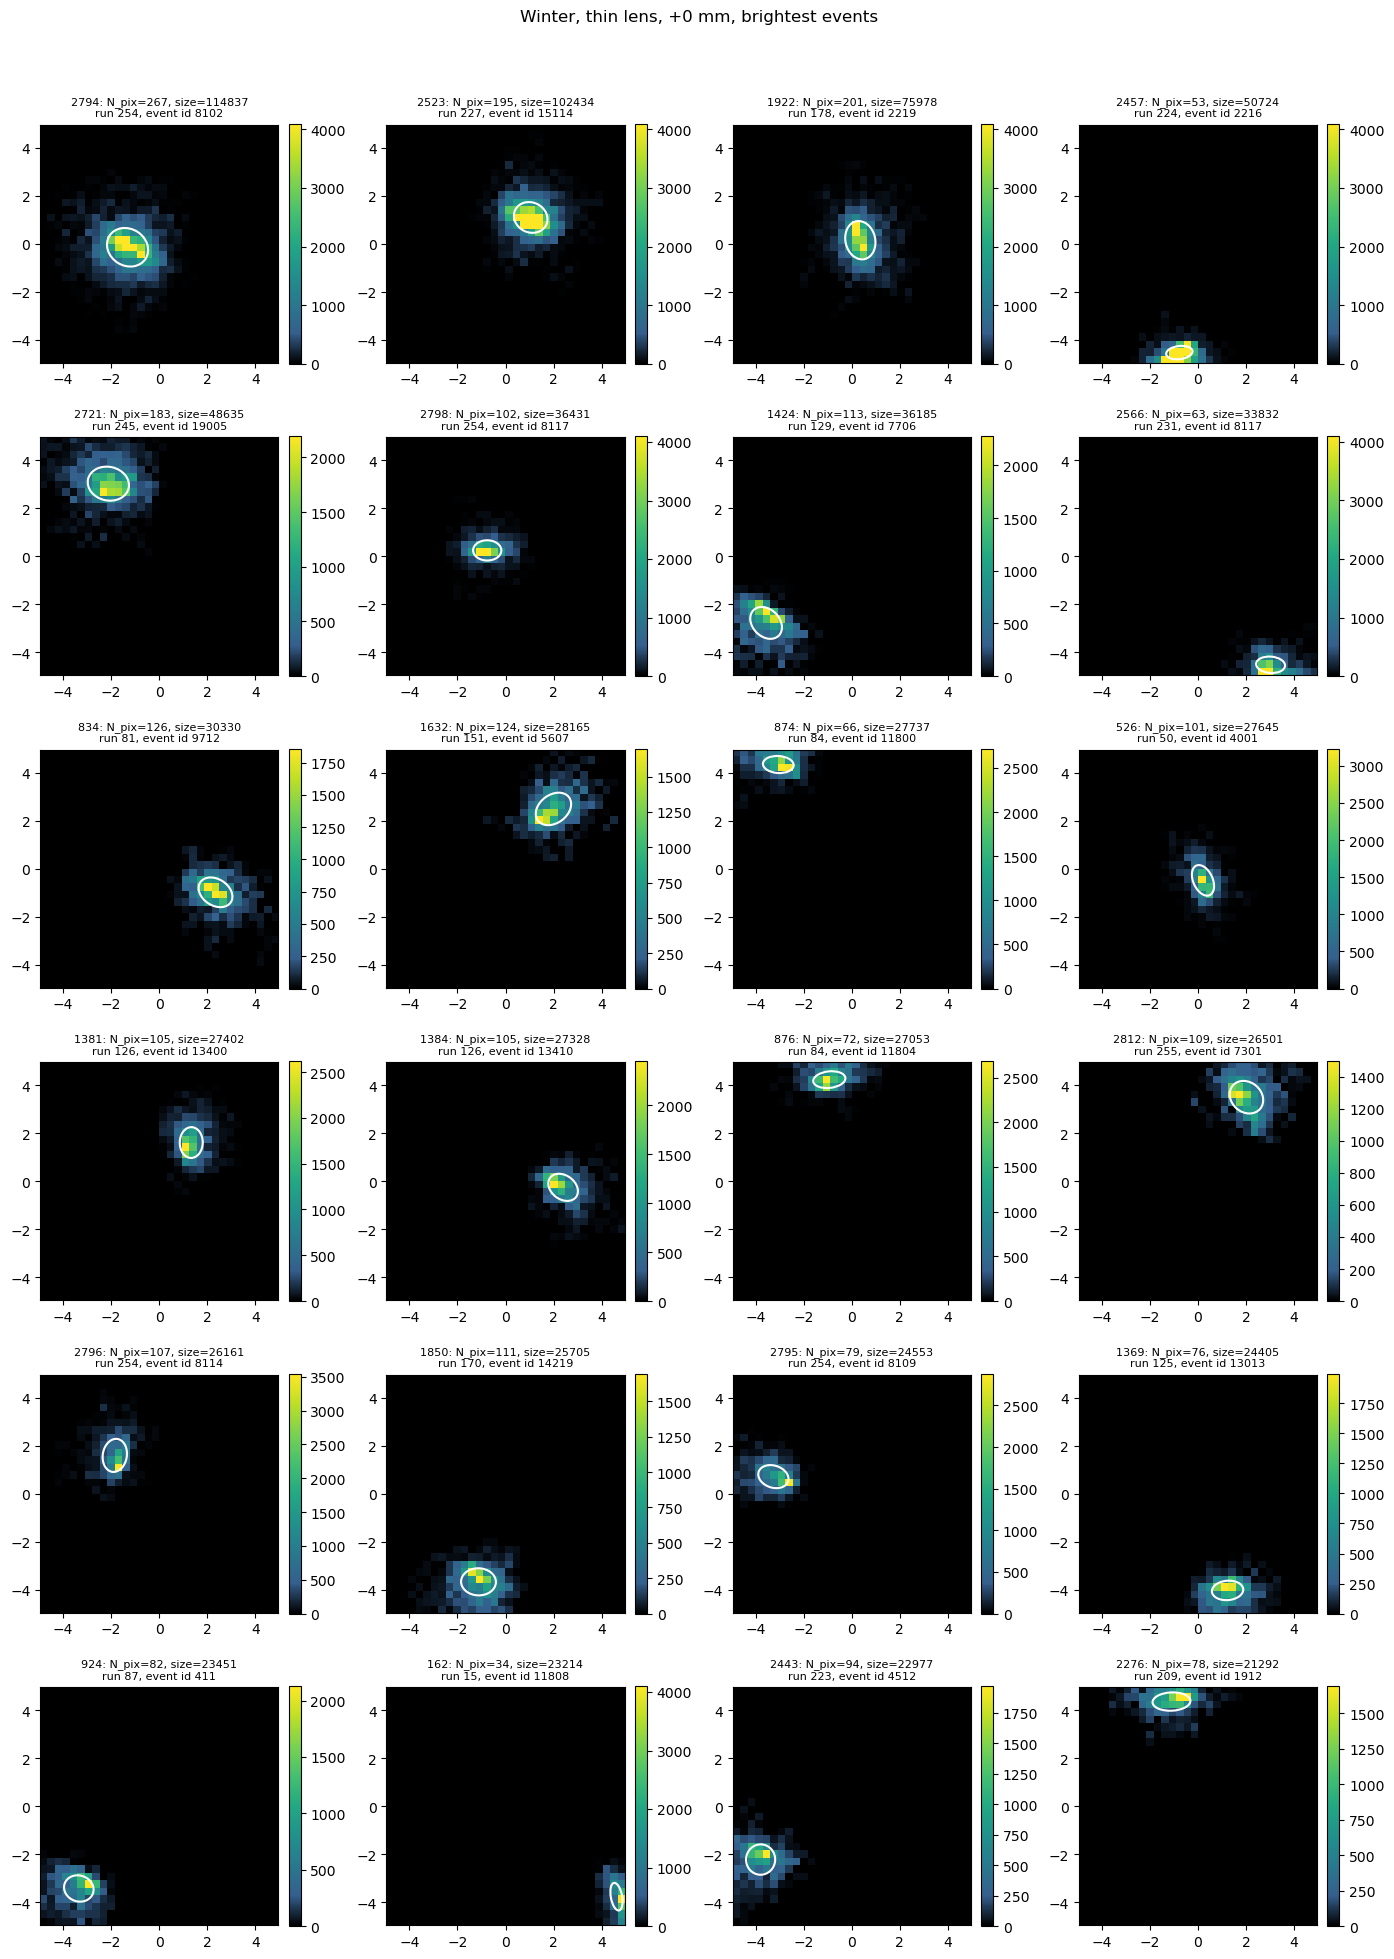

In [18]:
fig = plot_image_grid(processed_path(step_cfg), name, f"T{TEL_ID}", step_df.nlargest(N_EVENTS, "size").ImageIndex)
fig.suptitle(f"{TELESCOPE}, {LENS} lens, {EVENT_STEP:+d} mm, brightest events", y=1.02)
plt.show()

# Centroids
Image centroids after cuts, `LENS` lens, all steps together, one bin per camera pixel.

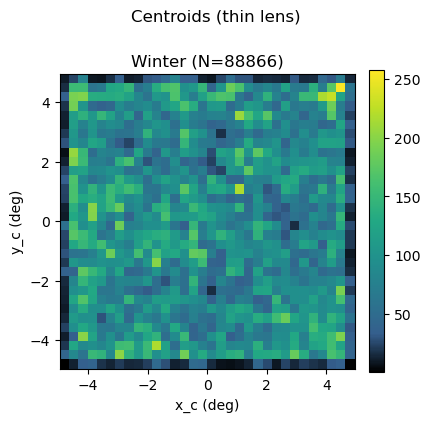

In [19]:
fig = dg.plot_centroids(df[df.Lens == LENS].assign(Telescope=TELESCOPE), title=f"Centroids ({LENS} lens)")
plt.show()